# Week 15 Final - Heart Sound Classification Project

This notebook demonstrates progress on the project **"Deep Learning-Based Heart Sound Classification Using CNN"**, as proposed. It includes:
- Data loading and preprocessing from the CIRCor dataset
- Feature extraction using **MFCCs**
- A custom **CNN architecture** trained on the processed dataset
- Accuracy tracking over epochs

This implementation serves as a stable foundation for further evaluation, spectrogram integration, and model comparison in the next phase.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Imports**

In [2]:
import os
import glob
import librosa
import librosa.display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
import re
import random

In [3]:
random.seed(42); np.random.seed(42); tf.keras.utils.set_random_seed(42)

## **Dataset**

In [4]:
DATASET_PATH = "/content/drive/MyDrive/training_data"

## **Generate MetaData**

In [5]:
txt_files = glob.glob(os.path.join(DATASET_PATH, "*.txt"))
metadata_list = []

for txt_file in txt_files:
    try:
        with open(txt_file, 'r') as f:
            lines = f.readlines()

        outcome = None
        wav_files = []

        for line in lines:
            line = line.strip()
            if line.lower().startswith("#outcome:"):
                outcome_match = re.search(r"#Outcome:\s*(\w+)", line, re.IGNORECASE)
                if outcome_match:
                    outcome = outcome_match.group(1).capitalize()
            if ".wav" in line.lower():
                parts = line.split()
                for part in parts:
                    if part.lower().endswith(".wav"):
                        full_path = os.path.join(DATASET_PATH, part)
                        if os.path.exists(full_path):
                            wav_files.append(part)

        if outcome in ["Normal", "Abnormal"]:
            for wav in wav_files:
                metadata_list.append({"filename": wav, "label": outcome})

    except Exception as e:
        print(f"Error processing {txt_file}: {e}")

metadata = pd.DataFrame(metadata_list)
print("Metadata generated. Number of labeled recordings:", len(metadata))
print(metadata.head())

Metadata generated. Number of labeled recordings: 2633
         filename     label
0    68363_AV.wav  Abnormal
1    68363_MV.wav  Abnormal
2  50743_AV_1.wav    Normal
3  50743_AV_2.wav    Normal
4  50743_AV_3.wav    Normal


## **Data Augmentation for Abnormal Samples**

In [6]:
def augment_audio(signal, sr):
    if random.random() < 0.5:
        signal = librosa.effects.time_stretch(signal, rate=random.uniform(0.8, 1.2))
    if random.random() < 0.5:
        signal = librosa.effects.pitch_shift(signal, sr=sr, n_steps=random.randint(-2, 2))
    if random.random() < 0.5:
        noise_amp = 0.005 * np.random.uniform() * np.amax(signal)
        signal = signal + noise_amp * np.random.normal(size=signal.shape)
    return signal

## **Multi-Channel Spectrogram Feature Extraction(3-Channel)**

In [7]:
def extract_spectrogram_3ch(file_path, label=None, max_len=5, n_mels=128):
    try:
        y, sr = librosa.load(file_path, sr=None)
        y = y[:sr * max_len]
        if len(y) < sr * max_len:
            y = np.pad(y, (0, sr * max_len - len(y)))

        if label == "Abnormal":
            y = augment_audio(y, sr)

        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_mels)
        mel_db = librosa.power_to_db(mel, ref=np.max)

        delta = librosa.feature.delta(mel_db)
        delta2 = librosa.feature.delta(mel_db, order=2)

        combined = np.stack([mel_db, delta, delta2], axis=-1)

        if combined.shape[1] < 128:
            pad_width = 128 - combined.shape[1]
            combined = np.pad(combined, ((0, 0), (0, pad_width), (0, 0)))
        else:
            combined = combined[:, :128, :]

        return combined
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

## **Extract Features**

In [8]:
label_map = {"Normal": 0, "Abnormal": 1}
X, y = [], []

for idx, row in metadata.iterrows():
    file_path = os.path.join(DATASET_PATH, row["filename"])
    spec = extract_spectrogram_3ch(file_path, label=row["label"])
    if spec is not None:
        X.append(spec)
        y.append(label_map[row["label"]])

X = np.array(X)
y = np.array(y)
print("Feature shape with 3 channels:", X.shape)  # (N, 128, 128, 3)

Feature shape with 3 channels: (2633, 128, 128, 3)


In [9]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# Number of folds
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

# Store metrics for each fold
acc_list, recall_list, precision_list, f1_list = [], [], [], []

fold = 1
for train_index, val_index in skf.split(X, y):
    print(f"\n Fold {fold}/{n_splits}")
    X_train, X_val = X[train_index], X[val_index]
    y_train, y_val = y[train_index], y[val_index]

    # Rebuild model from scratch for each fold
    model = models.Sequential([
        layers.Input(shape=(128, 128, 3)),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    # Early stopping
    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    # Compute class weights
    class_weights_array = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
    class_weight = dict(zip(np.unique(y_train), class_weights_array))

    # Train
    history = model.fit(
        X_train, y_train,
        epochs=20,
        batch_size=32,
        validation_data=(X_val, y_val),
        callbacks=[early_stop],
        class_weight=class_weight,
        verbose=0
    )

    # Predict & evaluate
    y_pred = (model.predict(X_val) > 0.5).astype("int32")
    acc = accuracy_score(y_val, y_pred)
    report = classification_report(y_val, y_pred, output_dict=True, zero_division=0)

    acc_list.append(acc)
    # Handle Abnormal class (label 1) safely
    if "1" in report:
      recall_list.append(report["1"]["recall"])
      precision_list.append(report["1"]["precision"])
      f1_list.append(report["1"]["f1-score"])
    else:
      recall_list.append(0)
      precision_list.append(0)
      f1_list.append(0)


    abnormal_label = str(label_map["Abnormal"])  # usually '1'

    if abnormal_label in report:
        ab_recall = report[abnormal_label]["recall"]
    else:
        ab_recall = 0.0

    print(f"Fold {fold} Accuracy: {acc:.4f}, Abnormal Recall: {ab_recall:.4f}")
    fold += 1

# Print final averaged results
print("\n Cross-Validation Results (5-Fold Stratified):")
print(f"Average Accuracy: {np.mean(acc_list):.4f} ± {np.std(acc_list):.4f}")
print(f"Average Abnormal Recall: {np.mean(recall_list):.4f}")
print(f"Average Abnormal Precision: {np.mean(precision_list):.4f}")
print(f"Average Abnormal F1-score: {np.mean(f1_list):.4f}")


 Fold 1/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step
Fold 1 Accuracy: 0.7268, Abnormal Recall: 0.7878

 Fold 2/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step
Fold 2 Accuracy: 0.6053, Abnormal Recall: 0.1592

 Fold 3/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step
Fold 3 Accuracy: 0.6129, Abnormal Recall: 0.8531

 Fold 4/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step
Fold 4 Accuracy: 0.7719, Abnormal Recall: 0.5410

 Fold 5/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step
Fold 5 Accuracy: 0.8099, Abnormal Recall: 0.6189

 Cross-Validation Results (5-Fold Stratified):
Average Accuracy: 0.7053 ± 0.0829
Average Abnormal Recall: 0.5920
Average Abnormal Precision: 0.8163
Average Abnormal F1-score: 0.6224


##**Train-Test Split**

In [10]:
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42, stratify=y
# )

# unique, counts = np.unique(y_train, return_counts=True)
# print("Train class distribution:", dict(zip(unique, counts)))

## **Build CNN Model**

In [11]:
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 126, 126, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 61, 61, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

## **Train Model with EarlyStopping + Class Weights**

In [12]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

class_weights_array = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weight = dict(zip(np.unique(y_train), class_weights_array))
print("Computed class weights:", class_weight)

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    class_weight=class_weight
)

Computed class weights: {np.int64(0): np.float64(0.9339539007092199), np.int64(1): np.float64(1.0760980592441267)}
Epoch 1/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 16s 139ms/step - accuracy: 0.7276 - loss: 0.5448 - val_accuracy: 0.6217 - val_loss: 0.6740
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.7860 - loss: 0.4737 - val_accuracy: 0.6578 - val_loss: 0.6304
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.8045 - loss: 0.4488 - val_accuracy: 0.7548 - val_loss: 0.5113
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.8092 - loss: 0.4350 - val_accuracy: 0.8023 - val_loss: 0.4555
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.8192 - loss: 0.4155 - val_accuracy: 0.4696 - val_loss: 1.2161
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.8296 - loss: 0.4038 - val_accuracy: 0.8232 - val_loss: 0.4435
Epoch 7/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.8287 - loss: 0.3973 - val_accuracy: 0.6882 - val_

## **Plot Accuracy**

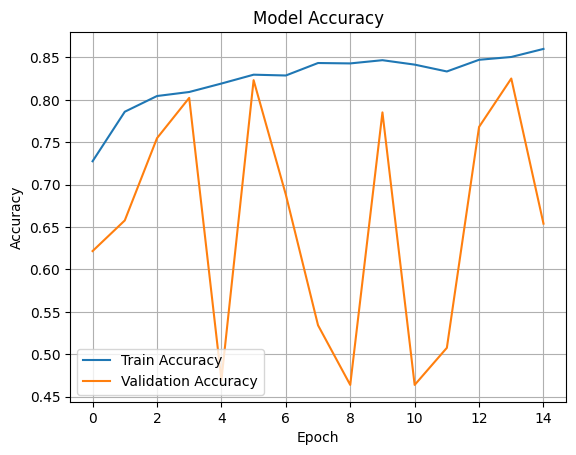

In [13]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

## **Evaluate Model: Confusion Matrix & Report**

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step
 Classification Report:
              precision    recall  f1-score   support

      Normal       0.80      0.80      0.80       282
    Abnormal       0.77      0.76      0.77       244

    accuracy                           0.79       526
   macro avg       0.78      0.78      0.78       526
weighted avg       0.79      0.79      0.79       526



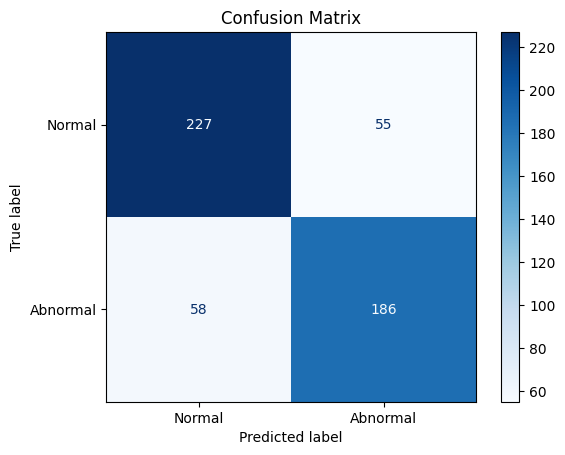

In [14]:
y_pred = (model.predict(X_val) > 0.5).astype("int32")

print(" Classification Report:")
print(classification_report(y_val, y_pred, target_names=["Normal", "Abnormal"]))

cm = confusion_matrix(y_val, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Abnormal"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

## **Visualize Sample Heart Sound & MFCC**

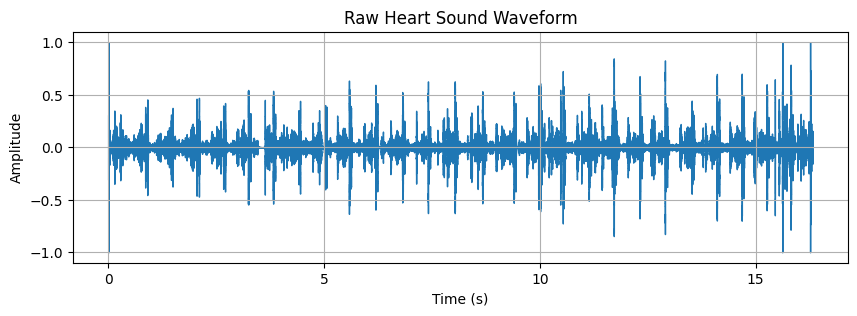

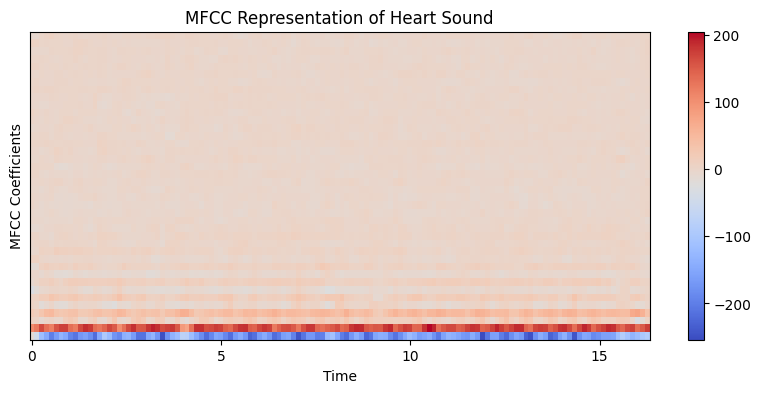

In [15]:
import librosa.display

# Use any file for demonstration
demo_file = os.path.join(DATASET_PATH, metadata.iloc[0]["filename"])
signal, sr = librosa.load(demo_file, sr=None)

# Waveform
plt.figure(figsize=(10, 3))
librosa.display.waveshow(signal, sr=sr)
plt.title("Raw Heart Sound Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

# MFCC
mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=40)
plt.figure(figsize=(10, 4))
librosa.display.specshow(mfcc, x_axis='time', sr=sr)
plt.colorbar()
plt.title("MFCC Representation of Heart Sound")
plt.xlabel("Time")
plt.ylabel("MFCC Coefficients")
plt.show()

## **Explorary Datat Analysis**

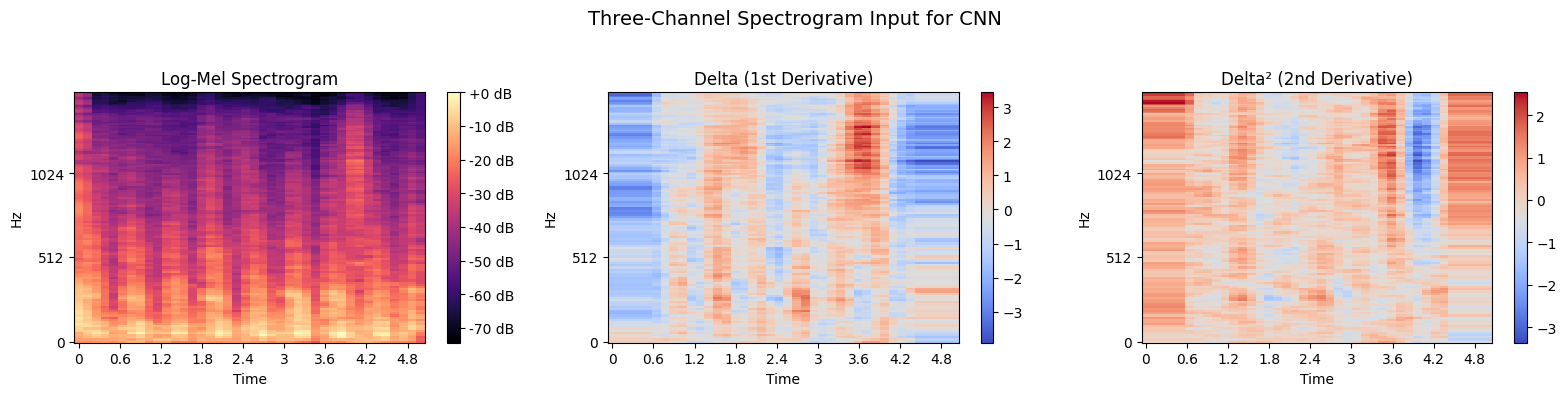

In [16]:
sample_file = os.path.join(DATASET_PATH, "68363_AV.wav")

# Load audio
y, sr = librosa.load(sample_file, sr=None)
y = y[:sr * 5]
if len(y) < sr * 5:
    y = np.pad(y, (0, sr * 5 - len(y)))

# Compute log-mel spectrogram
mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
mel_db = librosa.power_to_db(mel, ref=np.max)

# Compute delta and delta²
delta = librosa.feature.delta(mel_db)
delta2 = librosa.feature.delta(mel_db, order=2)

# Plot all three
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
librosa.display.specshow(mel_db, x_axis='time', y_axis='mel', sr=sr)
plt.title('Log-Mel Spectrogram')
plt.colorbar(format='%+2.0f dB')

plt.subplot(1, 3, 2)
librosa.display.specshow(delta, x_axis='time', y_axis='mel', sr=sr)
plt.title('Delta (1st Derivative)')
plt.colorbar()

plt.subplot(1, 3, 3)
librosa.display.specshow(delta2, x_axis='time', y_axis='mel', sr=sr)
plt.title('Delta² (2nd Derivative)')
plt.colorbar()

plt.suptitle('Three-Channel Spectrogram Input for CNN', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()